# Lab 3: K-Means and K-Medoids Clustering on the Wine Dataset

Name: Sandip Sitaula
Course: MSCS 634 - Advanced Big Data and Data Mining
Lab: Lab 3 - K-Means and K-Medoids Clustering

## Step 1: Load and prepare the dataset

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import kmedoids
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, adjusted_rand_score, pairwise_distances

wine = load_wine()
X, y = wine.data, wine.target
df = pd.DataFrame(X, columns=wine.feature_names)
print('Shape:', df.shape)
print('Missing values:', df.isna().sum().sum())
df.describe().T[['mean', 'std', 'min', 'max']]

Shape: (178, 13)
Missing values: 0


,mean,std,min,max
alcohol,13.000618,0.811827,11.03,14.83
malic_acid,2.336348,1.117146,0.74,5.80
ash,2.366517,0.274344,1.36,3.23
alcalinity_of_ash,19.494944,3.339564,10.60,30.00
magnesium,99.741573,14.282484,70.00,162.00
total_phenols,2.295112,0.625851,0.98,3.88
flavanoids,2.029270,0.998859,0.34,5.08
nonflavanoid_phenols,0.361854,0.124453,0.13,0.66
proanthocyanins,1.590899,0.572359,0.41,3.58
color_intensity,5.058090,2.318286,1.28,13.00


class_0    59
class_1    71
class_2    48
Name: count, dtype: int64


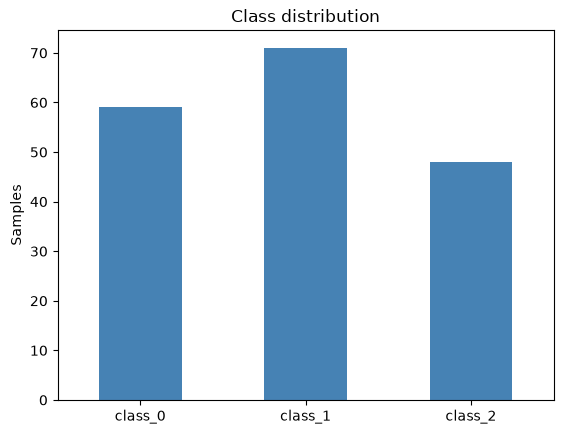

In [2]:
counts = pd.Series(y).map(dict(enumerate(wine.target_names))).value_counts().sort_index()
print(counts)
counts.plot(kind='bar', color='steelblue', title='Class distribution')
plt.ylabel('Samples')
plt.xticks(rotation=0)
plt.show()

The dataset has 178 wines, 13 numeric features, no missing values, and 3 classes (59, 71, and 48 wines). The features have very different sizes. For example, proline goes up to about 1680 while hue is around 1. Distance-based clustering needs the features on the same scale, so I standardize them with z-score.

In [3]:
scaler = StandardScaler()
Z = scaler.fit_transform(X)
print('Means (should be about 0):', np.round(Z.mean(axis=0), 2))
print('Std devs (should be 1):', np.round(Z.std(axis=0), 2))

Means (should be about 0): [ 0.  0. -0. -0. -0. -0.  0. -0. -0. -0.  0.  0. -0.]
Std devs (should be 1): [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


The class labels are not used for clustering. I only use them later to check the clusters with the Adjusted Rand Index (ARI).

## Step 2: K-Means clustering

In [4]:
kmeans = KMeans(n_clusters=3, n_init=10, random_state=42)
km_labels = kmeans.fit_predict(Z)

km_sil = silhouette_score(Z, km_labels)
km_ari = adjusted_rand_score(y, km_labels)
print(f'K-Means  silhouette = {km_sil:.3f}   ARI = {km_ari:.3f}')
print('Cluster sizes:', np.bincount(km_labels))

K-Means  silhouette = 0.285   ARI = 0.897
Cluster sizes: [65 51 62]


## Step 3: K-Medoids clustering

scikit-learn does not include K-Medoids. The usual add-on, scikit-learn-extra, did not work with the newer numpy and scikit-learn versions here. So I used the kmedoids package (FasterPAM algorithm). It takes a distance matrix, and I use Euclidean distance so the comparison with K-Means is fair.

In [5]:
dist = pairwise_distances(Z, metric='euclidean')
result = kmedoids.fasterpam(dist, 3, random_state=42)
med_labels = result.labels
med_idx = result.medoids

med_sil = silhouette_score(Z, med_labels)
med_ari = adjusted_rand_score(y, med_labels)
print(f'K-Medoids  silhouette = {med_sil:.3f}   ARI = {med_ari:.3f}')
print('Cluster sizes:', np.bincount(med_labels))
print('Medoid rows (real wines from the data):', med_idx)

K-Medoids  silhouette = 0.268   ARI = 0.741
Cluster sizes: [55 74 49]
Medoid rows (real wines from the data): [106  35 148]


In [6]:
pd.DataFrame({'Silhouette': [km_sil, med_sil], 'ARI': [km_ari, med_ari]},
             index=['K-Means', 'K-Medoids']).round(3)

,Silhouette,ARI
K-Means,0.285,0.897
K-Medoids,0.268,0.741


## Step 4: Visualize and compare

The data has 13 features, so I use PCA to show it in 2 dimensions. The clustering itself was done on all 13 features. The centroids and medoids are moved into the same 2D space.

Variance explained by the 2 components: 0.554


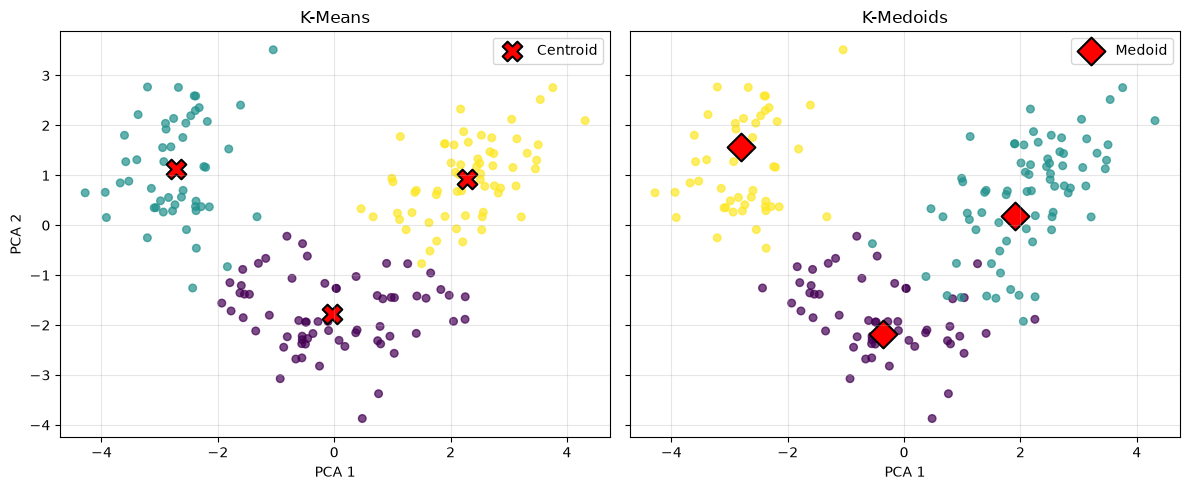

In [7]:
pca = PCA(n_components=2)
P = pca.fit_transform(Z)
print('Variance explained by the 2 components:', pca.explained_variance_ratio_.round(3).sum().round(3))

km_centers = pca.transform(kmeans.cluster_centers_)
med_centers = P[med_idx]

fig, ax = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
panels = [(ax[0], km_labels, km_centers, 'K-Means', 'X'),
          (ax[1], med_labels, med_centers, 'K-Medoids', 'D')]
for a, labels, centers, name, marker in panels:
    a.scatter(P[:, 0], P[:, 1], c=labels, cmap='viridis', s=30, alpha=0.7)
    a.scatter(centers[:, 0], centers[:, 1], c='red', marker=marker, s=200,
              edgecolor='black', linewidth=1.5, label='Centroid' if name == 'K-Means' else 'Medoid')
    a.set_title(name)
    a.set_xlabel('PCA 1')
    a.legend()
    a.grid(alpha=0.3)
ax[0].set_ylabel('PCA 2')
plt.tight_layout()
plt.show()

To see how well the clusters match the real classes, here is the same plot colored by the true wine class.

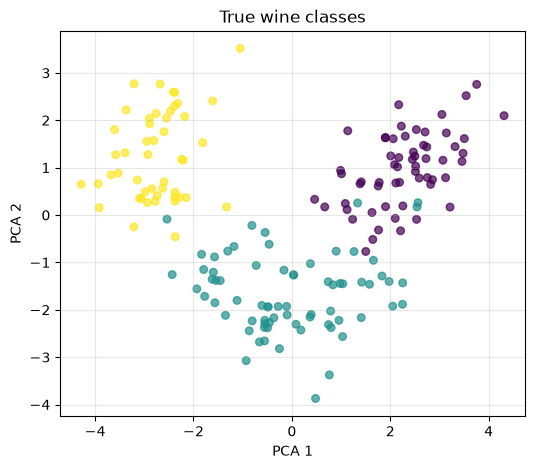

K-Means cluster   0   1   2
true class                 
0                 0   0  59
1                65   3   3
2                 0  48   0

K-Medoids cluster   0   1   2
true class                   
0                   0  59   0
1                  55  15   1
2                   0   0  48


In [8]:
plt.figure(figsize=(6, 5))
plt.scatter(P[:, 0], P[:, 1], c=y, cmap='viridis', s=30, alpha=0.7)
plt.title('True wine classes')
plt.xlabel('PCA 1')
plt.ylabel('PCA 2')
plt.grid(alpha=0.3)
plt.show()
print(pd.crosstab(y, km_labels, rownames=['true class'], colnames=['K-Means cluster']))
print()
print(pd.crosstab(y, med_labels, rownames=['true class'], colnames=['K-Medoids cluster']))

### Observations

Which algorithm made better clusters? K-Means did, but only a little by silhouette score (0.285 vs 0.268). Both scores are low, which means the clusters touch or overlap somewhat. The bigger difference is the ARI: 0.897 for K-Means and 0.741 for K-Medoids. K-Means matched the real wine classes much better. It got 59 of 59 class 0 wines and 48 of 48 class 2 wines in their own clusters, and only 6 class 1 wines were misplaced. K-Medoids put 15 class 1 wines in the class 0 cluster.

Shapes and positions: In the PCA plot, both methods find three groups in about the same places. The difference is at the border between the class 0 and class 1 groups, where the points overlap. K-Medoids drew that border a bit differently, so its cluster sizes (55, 74, 49) are different from K-Means (65, 51, 62). The K-Means centroids are averages, so they can sit anywhere. The K-Medoids centers are real wines from the data, so each one sits on an actual point. Keep in mind that PCA keeps only 55% of the variance, so some overlap in the 2D picture may not exist in the full 13 features.

When to use which:
- K-Means is a good choice when the features are numeric and scaled, the clusters are roughly round, and the data has no big outliers. It is fast and gave the best result here.
- K-Medoids is better when the data has outliers, because a single extreme point can pull a K-Means average away but cannot do that to a medoid. It is also useful when you need each cluster center to be a real example, or when you want to use a distance other than Euclidean. The cost is that it is slower on big datasets.
- On this clean, scaled dataset there are no strong outliers, so K-Medoids had no advantage to use.

Limits: This is one dataset and one run with a fixed random seed. K-Medoids can give a different result with a different start, so I would not say K-Medoids is always worse.